---
title: "4.2 · Use with other providers: Bundesliga example"
---

This is part 4.2 of the [User guide](../../usage.qmd), following the [data requirements and preparation guide](../../external-data.qmd). It applies the installed PRESS models to match J03WMX (27 May 2023). Original event and tracking XML are from IDSSE, provided by the Deutsche Fußball Liga (DFL), under CC BY 4.0 [@bassek2025idsse; @idsse-repository]. Download the original data through the [official repository](https://github.com/spoho-datascience/idsse-data).

DataBallPy 0.7.3 is used as an optional external preprocessing tool for alignment and a tracking-based control estimate [@oonk2026databallpy; @databallpy-repository]. PRESS performs the canonical segmentation and context reconstruction. All models are used as fitted. The example demonstrates software interoperability, and predictive generalization to Bundesliga data remains to be assessed. [Input requirements and limitations](../../external-data.qmd).

## Original files and synchronization

Install PRESS with its `io` extra. In a separate Python 3.10 environment install `databallpy==0.7.3` and `pyarrow`. Set `PRESS_IDSSE_DATA` to the downloaded XML directory and `PRESS_SYNC_PYTHON` to that environment's Python executable. `PRESS_IDSSE_OUTPUT` optionally selects a cache/output directory. The bridge reads the original XML, refines alignment and exports tables. The source files remain unchanged.

Events unsupported by the synchronizer retain a different provenance if their clock is interpolated between nearby aligned anchors; unlinked events remain unmatched. Already aligned bridge outputs can be reused explicitly.

In [3]:
import os
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PRESS import PRESS
from PRESS.io import segment_possessions
from PRESS.visualization import plot_frame, plot_pass_map, plot_bcos
from examples.preprocessing.idsse import prepare_idsse

raw_dir = Path(os.environ["PRESS_IDSSE_DATA"])
output_dir = Path(os.environ.get("PRESS_IDSSE_OUTPUT", "data/external/idsse/J03WMX"))
already_prepared = (output_dir / "aligned/alignment.json").is_file()
tracking, events, players, metadata = prepare_idsse(
    raw_dir, "J03WMX", output_dir,
    synchronize=not already_prepared,
    sync_python=os.environ.get("PRESS_SYNC_PYTHON"),
)
print(metadata["home_team"], "–", metadata["away_team"])
print("Tracking:", len(tracking), "frames at", metadata["fps"], "Hz")
display(events.groupby("sync_method").size().rename("events").to_frame())

1. FC Köln – FC Bayern München
Tracking: 145967 frames at 25.0 Hz


,events
sync_method,
databallpy,1168
interpolated_clock,306
unmatched,133


## Canonical input and custom segmentation

DataBallPy's static home/away coordinates already orient the home side towards positive x in both periods. They keep that orientation. The adapter maps provider/player IDs to stable home/away aliases, keeps native pitch metres, differentiates finite contiguous position runs, and reconstructs past score and clock context.

Restart qualifiers and identified subsequent control distinguish receptions and interceptions from open play, throw-ins, corners, free kicks and goal kicks. Unknown origins stay `unknown`, a category accepted by the existing fitted encoders. A recovery requires more than contact. The carrier stream is estimated, so these intervals are estimates, distinct from annotated SkillCorner possessions.

Individual possession intervals may instead be supplied by external preprocessing. PRESS constructs its canonical actions and checkpoints at initialization when `actions_data` is omitted. The one-second action convention is implemented in `PRESS.io.canonical_actions`; which replaces provider action segmentation.


In [5]:
print("Player sample")
display(players[["player_id", "source_player_id", "full_name", "team_id"]].head())
display(events[["event_id", "event_type", "player_id", "receiver_player_id",
                "is_successful", "restart_type", "frame", "sync_method"]].head())
tracking, individuals, _, report = segment_possessions(
    tracking, events, fps=metadata["fps"], match_id=metadata["match_id"],
)
press = PRESS(
    tracking, player_possessions_data=individuals,
    fps=metadata["fps"], match_id=metadata["match_id"], player_metadata=players,
    pitch_length=metadata["pitch_length"], pitch_width=metadata["pitch_width"],
)
print(json.dumps(report, indent=2))

Player sample
{
  "n_individual_possessions": 1375,
  "n_actions": 5308,
  "n_unverified_outcomes": 526,
  "unverified_successful_receptions": 62,
  "policy": "one_second_actions_with_exposure_tails_v2",
  "control_source": "supplied control stream; may be tracking-estimated",
  "one_frame_reception_fallback": false,
  "n_events": 1607,
  "n_matched_events": 1474
}


,player_id,source_player_id,full_name,team_id
0,away_27,DFL-OBJ-0002DR,Yann Sommer,away
2,away_13,DFL-OBJ-0000RP,Eric Maxim Choupo-Moting,away
3,away_25,DFL-OBJ-0000IA,Thomas Müller,away
5,away_8,DFL-OBJ-000191,Leon Christoph Goretzka,away
7,away_7,DFL-OBJ-0027G6,Serge David Gnabry,away


,event_id,event_type,player_id,receiver_player_id,is_successful,restart_type,frame,sync_method
0,18226500000006,pass,away_7,away_2,True,kick_off,10000,databallpy
1,18226500000007,pass,away_2,None,False,open_play,10042,databallpy
2,18226500000008,pass,home_2,away_2,False,throw_in,10426,databallpy
3,18226500000009,tackle,away_2,None,<NA>,unknown,10518,databallpy
4,18226500000010,unknown,away_2,None,<NA>,unknown,10524,interpolated_clock


In [6]:
possessions = press.get_player_possessions()
canonical_actions = press.get_actions()
display(possessions.groupby(["start_type", "end_type"]).size().rename("possessions").to_frame())
display(canonical_actions.groupby("action").size().rename("actions").to_frame())

possessions
start_type             end_type                  
corner_interception    unknown                  5
corner_reception       pass                     2
free_kick_interception unknown                  2
free_kick_reception    pass                    12
                       unknown                  1
goal_kick_reception    pass                    11
                       unknown                  1
pass_interception      pass                    49
                       shot                     1
                       unknown                 66
pass_reception         foul_suffered            1
                       pass                   568
                       shot                     7
                       unknown                 86
throw_in_interception  pass                     4
                       unknown                  5
throw_in_reception     pass                    25
                       unknown                  9
unknown                foul_suffered            1
                       pass                   233
                       shot                     5
                       unknown                281

,actions
action,
ball_drive,3496
pass,904


## One observed possession

Select an outfield reception followed by a verified completed pass, with at least two whole seconds of carrying. Among eligible controls, use the first chronological case whose initial ball is within the 1.5 m control zone and an opponent is within eight metres. This is an illustrative selection.

The rule selects Leroy Sané (Bayern), followed by a completed pass to Benjamin Pavard. The start, whole-second carry checkpoints and release are different canonical decision states. The next control illustrates the annotated outcome; the state predictors use only information up to the checkpoint.

In [8]:
outfield = set(players.loc[players.is_goalkeeper.eq(False), "player_id"])
candidates = possessions.loc[
    possessions.outcome_verified & possessions.end_type.eq("pass")
    & possessions.start_type.eq("pass_reception") & possessions.frame_receipt.notna()
    & possessions.player_id.isin(outfield)
    & (possessions.frame_end-possessions.frame_start).between(2*press.fps, 5*press.fps)
].sort_values("frame_start")
selected = None
for row in candidates.itertuples():
    state = press.get_state(int(row.frame_start))
    ball = press.get_frame(int(row.frame_start))[["ball_x", "ball_y"]].to_numpy()[0]
    nearest = np.linalg.norm(state["r_defs"]-state["x_bc"], axis=1).min()
    if np.linalg.norm(ball-state["x_bc"]) < 1.5 and nearest < 8:
        selected = row
        break
if selected is None:
    raise ValueError("No case meets the documented selection rule; inspect the preparation report.")
selected_actions = press.get_actions(possession_id=selected.possession_id)
frames = selected_actions.frame_start.astype(int).tolist()
name = players.set_index("player_id").full_name
print(name[selected.player_id], "→", name[selected.target_pass])
display(selected_actions[["frame_start", "frame_end", "action", "previous_action", "time_since_start", "outcome"]])

Leroy Aziz Sané → Benjamin Jacques Marcel Pavard


,frame_start,frame_end,action,previous_action,time_since_start,outcome
0,10613,10638,ball_drive,pass_reception,0.00,1
1,10638,10663,ball_drive,ball_drive,1.00,1
2,10663,10688,ball_drive,ball_drive,2.00,1
3,10688,10713,ball_drive,ball_drive,3.00,1
4,10722,10722,pass,ball_drive,4.36,1


## Complete PRESS inference

Each checkpoint uses the production pass-risk, ball-drive, pass-selection, action-selection and residual-risk models. The predictors receive only information available at the checkpoint. h describes current-action fragility; xLoss additionally includes predicted loss after that action succeeds. Each checkpoint computes only the preliminary effective-hazard BCOS required by the frozen classifiers, pending retraining. The final transport map is requested separately for the single descriptive example below.

In [10]:
predictions = []
for frame in frames:
    # Retain spatial fields only for the checkpoint plotted below.
    press.compute_risk_frame(frame, include_residual=True, keep_details=(frame == frames[0]))
    predictions.append(dict(
        frame=frame, elapsed_seconds=press.get_elapsed_time(frame),
        p_pass=press.get_action_selection_result(frame)["Pass probability"],
        drive_loss=press.get_ball_drive_risk_result(frame)["Ball drive risk"],
        h=press.get_hazard_result(frame)["Hazard"],
        residual_loss=press.get_residual_risk_result(frame)["Residual loss probability"],
        xloss=press.get_xloss_result(frame)["xLoss"],
        bcos_feature_m2=press.get_bcos_result(frame)["BCOS area"],
    ))
checkpoint_summary = pd.DataFrame(predictions)
display(checkpoint_summary.round(4))
checkpoint_summary.to_csv(output_dir / "checkpoint_predictions.csv", index=False)
print("Observed terminal action:", selected.end_type, selected.pass_outcome)
print("Mean h:", checkpoint_summary.h.mean(), "· maximum h:", checkpoint_summary.h.max())

Observed terminal action: pass successful
Mean h: 0.12397770699900339 · maximum h: 0.27746501423312775


,frame,elapsed_seconds,p_pass,drive_loss,h,residual_loss,xloss,bcos_feature_m2
0,10613,0.00,0.0965,0.0028,0.0372,0.1333,0.1573,111.3092
1,10638,1.00,0.3354,0.0117,0.0764,0.1286,0.1609,76.5007
2,10663,2.00,0.2818,0.0585,0.1792,0.1972,0.3125,44.1077
3,10688,3.00,0.2723,0.1317,0.2775,0.3923,0.5253,38.9059
4,10722,4.36,0.7588,0.1286,0.0496,0.1327,0.0775,12.8298


These probabilities describe the fitted model's assessment of the observed states. Agreement with one completed pass is a single observation and leaves cross-dataset calibration open. Differences in control detection, annotation granularity and competition can affect all contextual models; a held-out IDSSE outcome study would require independently verified targets.

## Pitch control and BCOS at the same frame

Both panels use the same real tracking state and the package plotting functions. Pitch control describes competition for a destination; BCOS describes reaching a destination without interception along a hypothetical route. The surfaces answer different questions.

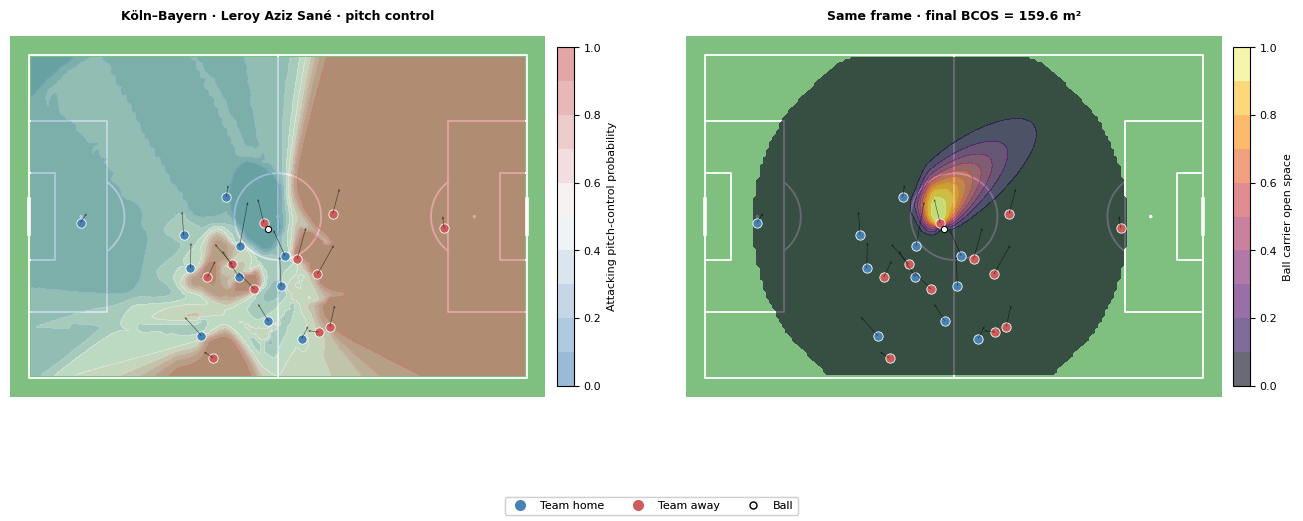

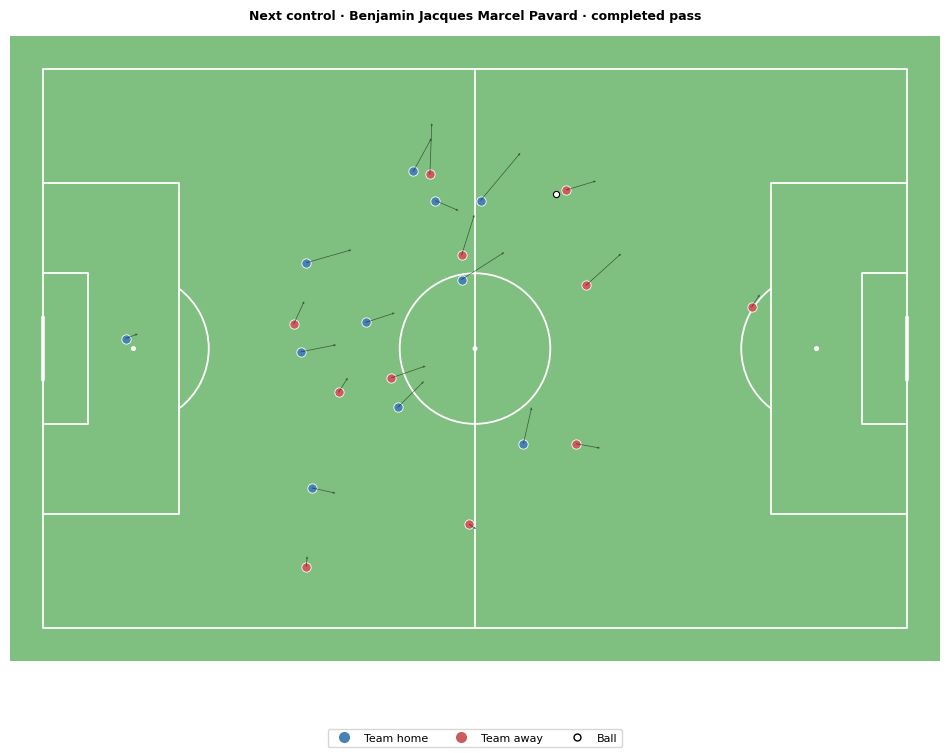

In [13]:
from PRESS.spatial_features import BCOS

frame = frames[0]
# Optional descriptor requested for this plot, independently of classifier inference.
bcos_display = BCOS(press.tracking_data, ball_drive_model=press.ball_drive_model)
bcos_display.compute_bcos(frame)  # Final transport by default.
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
plot_pass_map(press, frame, field="pitch_control", ax=axes[0], show=False,
              title=f"Köln–Bayern · {name[selected.player_id]} · pitch control")
plot_bcos(bcos_display, frame, ax=axes[1], show=False,
          title=f"Same frame · final BCOS = {bcos_display.get_result(frame)['BCOS area']:.1f} m²")
plt.show()
plot_frame(press, int(selected.frame_receipt),
           title=f"Next control · {name[selected.target_pass]} · completed pass")
plt.show()

## Outputs and reproducibility

The object holds copied tracking/annotations and separate numerical component caches. The input tables, alignment report and segmentation audit remain distinct from model outputs. Saving numerical results leaves the original IDSSE data at its source.

In [15]:
print("Stored result components:", list(press.get_results()))
print("BCOS classifier feature:", press.get_result_configuration(frame)["ACTION_SELECTION"]["BCOS feature formulation"])
press.player_possessions_data.to_parquet(output_dir / "possessions.parquet", index=False)
press.actions_data.to_parquet(output_dir / "actions.parquet", index=False)
(output_dir / "segmentation.json").write_text(json.dumps(report, indent=2))
press.save_results(output_dir / "results", overwrite=True)
print("Saved input annotations, audit, checkpoint table and numerical results.")

Stored result components: ['PPCF', 'BALL_DRIVE_RISK', 'ACTION_SELECTION', 'HAZARD', 'BCOS', 'RESIDUAL_RISK', 'XLOSS']
BCOS classifier feature: effective_hazard
Saved input annotations, audit, checkpoint table and numerical results.


## References and data credit

Data: Deutsche Fußball Liga (DFL), IDSSE, CC BY 4.0 [@bassek2025idsse; @idsse-repository]. Original data access and attribution instructions: [official IDSSE repository](https://github.com/spoho-datascience/idsse-data). Synchronization/control software: DataBallPy, MIT license [@oonk2026databallpy; @databallpy-repository].